In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

import shap


## Data

In [ ]:
df = pd.read_csv("compas-scores-two-years.csv")
print(df.shape)
df.head()

(7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,juv_fel_count,decile_score,juv_misd_count,juv_other_count,priors_count,days_b_screening_arrest,c_jail_in,c_jail_out,c_case_number,c_offense_date,c_arrest_date,c_days_from_compas,c_charge_degree,c_charge_desc,is_recid,r_case_number,r_charge_degree,r_days_from_arrest,r_offense_date,r_charge_desc,r_jail_in,r_jail_out,violent_recid,is_violent_recid,vr_case_number,vr_charge_degree,vr_offense_date,vr_charge_desc,type_of_assessment,decile_score.1,score_text,screening_date,v_type_of_assessment,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,0,1,0,0,0,-1.0,2013-08-13 06:03:42,2013-08-14 05:41:20,13011352CF10A,2013-08-13,NaN,1.0,F,Aggravated Assault w/Firearm,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-08-14,Risk of Violence,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,0,3,0,0,0,-1.0,2013-01-26 03:45:27,2013-02-05 05:36:53,13001275CF10A,2013-01-26,NaN,1.0,F,Felony Battery w/Prior Convict,1,13009779CF10A,(F3),NaN,2013-07-05,Felony Battery (Dom Strang),NaN,NaN,NaN,1,13009779CF10A,(F3),2013-07-05,Felony Battery (Dom Strang),Risk of Recidivism,3,Low,2013-01-27,Risk of Violence,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,0,4,0,1,4,-1.0,2013-04-13 04:58:34,2013-04-14 07:02:04,13005330CF10A,2013-04-13,NaN,1.0,F,Possession of Cocaine,1,13011511MM10A,(M1),0.0,2013-06-16,Driving Under The Influence,2013-06-16,2013-06-16,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,4,Low,2013-04-14,Risk of Violence,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,0,8,1,0,1,NaN,NaN,NaN,13000570CF10A,2013-01-12,NaN,1.0,F,Possession of Cannabis,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,8,High,2013-01-13,Risk of Violence,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,0,1,0,0,2,NaN,NaN,NaN,12014130CF10A,NaN,2013-01-09,76.0,F,arrest case no charge,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-03-26,Risk of Violence,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [ ]:
df.columns

Index(['id', 'name', 'first', 'last', 'compas_screening_date', 'sex', 'dob',
       'age', 'age_cat', 'race', 'juv_fel_count', 'decile_score',
       'juv_misd_count', 'juv_other_count', 'priors_count',
       'days_b_screening_arrest', 'c_jail_in', 'c_jail_out', 'c_case_number',
       'c_offense_date', 'c_arrest_date', 'c_days_from_compas',
       'c_charge_degree', 'c_charge_desc', 'is_recid', 'r_case_number',
       'r_charge_degree', 'r_days_from_arrest', 'r_offense_date',
       'r_charge_desc', 'r_jail_in', 'r_jail_out', 'violent_recid',
       'is_violent_recid', 'vr_case_number', 'vr_charge_degree',
       'vr_offense_date', 'vr_charge_desc', 'type_of_assessment',
       'decile_score.1', 'score_text', 'screening_date',
       'v_type_of_assessment', 'v_decile_score', 'v_score_text',
       'v_screening_date', 'in_custody', 'out_custody', 'priors_count.1',
       'start', 'end', 'event', 'two_year_recid'],
      dtype='object')

ID – Unique person identification

Name – Full name of defendant

Firtst – First name of defendant

Last – Last name of defendant

C Case Number – Case number for current charge

C Rase Number – Case number for recidivism charge

Vr Case Number – Case number for later violent recidivism charge

Sex – Defendant sex as male or female

Dob – Date of Birth

Age – Age at COMPAS screening

Age Cat – Age group

Race – Race of category of defendant

Jub Fel Count  - Number of juvenile felony offenses

Juv Misd count – Number of juvenile misdemeanor offense

Juv Other Count – Number of other juvenile offenses

Priors Count – Number of prior offenses before the COMPAS  screening

Priors Count.1 – Duplicate version of priors count

C Charge Degree – Degree of current charge, F as felony or misdemeanor for M

C Charge Desc – Text description of current charge

C Offense Date – Date of current offense

C Arrest Date – Date of current arrest

C Days from COMPAS – Days between current charge and COMPAS
assessment

Days B Screening Arrest – Days between screening and arrest

C Jail In – Date defendant entered jail for current case

C Jail Out – Date defendant left jail for current case

Type of Assessment – Type of COMPAS assessment

Decile Score – COMPAS risk score from 1 to 10

Decile Score.1 – Duplicate COMPAS risk score

Score Text – COMPAS risk category, low, medium, high

Screening Date – Date of COMPAS screening

Compas Screening Date – COMPAS  screening date

V Type of Assessment – Violent risk assessment type

V decile score – COMPAS violent risk score from 1 to 10

V Score Text – COMPAS  violent risk category

V Screening Date – Violent risk screening date

Is Recid – Whether the person had a later recidivism event

Two Year Recid – Whether the person recidivated within two years

R Charge Degree – Degree of later recidivism charge

R Days from Arrest – Days from arrest to later recidivism event

R Offense Date – Date of later offense

R Charge Desc – Description of later recidivism charge

R Jail In – Jail entry date after recidivism

R Jail Out – Jail release date after recidivism

Violent Recid – Violent Recidivism marker

Is Violent Recid – Whether person had violent recidivism

Vr Charge Degree – Degree of violent recidivism charge

Vr Offense Date – Date of violent recidivism offense

Vr charge Desc – Description of violent recidivism charge

In Custody – Date person entered custody

Out Custody – Date person left custody

Start – Start of follow up period

End – End of follow up period

Event – Event indicator for survival analysis

Our main target is predicting two year recid. We will avoid the features that are included information about what happened after the screening. Additionally, we will drop the features that are personal identifiers for privacy, case numbers are administrative labels that does not explain whether someone will recidivate, the dates that are before COMPAS screening, jail related time or recidivism events that will accidently leak information from the future, the future recidivism information that describing after the person was assessed to avoid the model not to know future recidivism, and the COMPAS scores related that we want model to be more independent on algorithmic risk predictions.
So we will use the race, sex, age, age cat, priors count, c charge degree, decile score, score text, two year recid, jub fel count, juv misd count, and juv other count for main features.


In [ ]:
df_focus = df[["race",
    "sex",
    "age",
    "age_cat",
    "priors_count",
    "c_charge_degree",
    "decile_score",
    "score_text",
    "two_year_recid",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count"]]
df_focus.head()

,race,sex,age,age_cat,priors_count,c_charge_degree,decile_score,score_text,two_year_recid,juv_fel_count,juv_misd_count,juv_other_count
0,Other,Male,69,Greater than 45,0,F,1,Low,0,0,0,0
1,African-American,Male,34,25 - 45,0,F,3,Low,1,0,0,0
2,African-American,Male,24,Less than 25,4,F,4,Low,1,0,0,1
3,African-American,Male,23,Less than 25,1,F,8,High,0,0,1,0
4,Other,Male,43,25 - 45,2,F,1,Low,0,0,0,0


### Missing Values

Let's check the implicit and explicit missing values for data quality.

In [ ]:
df_focus.dtypes

,0
race,object
sex,object
age,int64
age_cat,object
priors_count,int64
c_charge_degree,object
decile_score,int64
score_text,object
two_year_recid,int64
juv_fel_count,int64


For numerical values, there is no implicit missing values that are showing int64 or float64. Let's check the categorical features.

In [ ]:
categoric = ["race", "sex", "age_cat", "c_charge_degree", "score_text"]

for i in categoric:
  print("--"*8)
  print(f"{i}")
  print(df_focus[f"{i}"].unique())

----------------
race
['Other' 'African-American' 'Caucasian' 'Hispanic' 'Native American'
 'Asian']
----------------
sex
['Male' 'Female']
----------------
age_cat
['Greater than 45' '25 - 45' 'Less than 25']
----------------
c_charge_degree
['F' 'M']
----------------
score_text
['Low' 'High' 'Medium']


There is no implicit missing values. Let's check explicit missing values.

In [ ]:
df_focus.isna().sum()

,0
race,0
sex,0
age,0
age_cat,0
priors_count,0
c_charge_degree,0
decile_score,0
score_text,0
two_year_recid,0
juv_fel_count,0


There is no missing values.

## Exploratory Data Analysis

Lets's check the race distribution

In [ ]:
race_distribution = (
    df_focus["race"]
    .value_counts()
    .reset_index()
)

race_distribution.columns = ["race", "count"]
race_distribution["percent"] = (
    race_distribution["count"] / len(df)
) * 100

race_distribution

,race,count,percent
0,African-American,3696,51.233712
1,Caucasian,2454,34.017189
2,Hispanic,637,8.830053
3,Other,377,5.225950
4,Asian,32,0.443582
5,Native American,18,0.249515


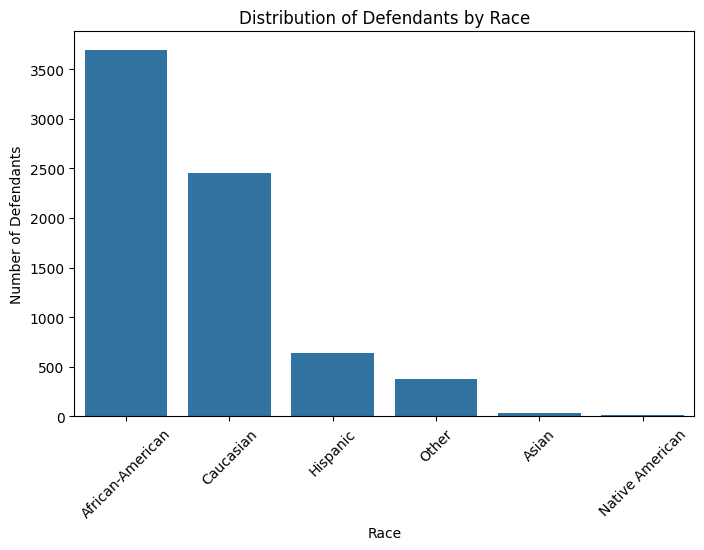

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_focus,
    x="race",
    order=df_focus["race"].value_counts().index
)

plt.title("Distribution of Defendants by Race")
plt.xlabel("Race")
plt.ylabel("Number of Defendants")
plt.xticks(rotation=45)
plt.show()

There are not evenly distributed across racial groups. The African-American was the highest among the group, then Caucasian. There are minority groups such as Native American and Asians in the data.

Let's check the class balance for target variable.

In [ ]:
class_balance = (
    df_focus["two_year_recid"]
    .value_counts()
    .sort_index()
    .reset_index()
)

class_balance.columns = ["two_year_recid", "count"]
class_balance["percent"] = (
    class_balance["count"] / len(df_focus)
) * 100

class_balance

,two_year_recid,count,percent
0,0,3963,54.934849
1,1,3251,45.065151


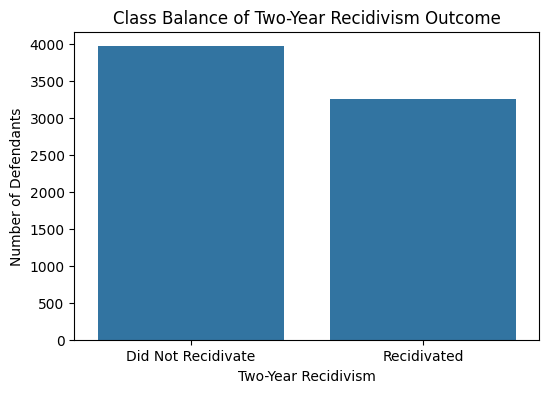

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_focus,
    x="two_year_recid"
)

plt.title("Class Balance of Two-Year Recidivism Outcome")
plt.xlabel("Two-Year Recidivism")
plt.ylabel("Number of Defendants")
plt.xticks(
    ticks=[0, 1],
    labels=["Did Not Recidivate", "Recidivated"]
)
plt.show()

The two year recidivism outcome is decent balanced that about 54.9% of defendants did not recidivate within two years, while about 45% did recidivate.

Let's check the recidivism rate by race

In [ ]:
recid_by_race = (
    df_focus
    .groupby("race")["two_year_recid"]
    .agg(["count", "mean"])
    .reset_index()
)

recid_by_race["recidivism_percent"] = recid_by_race["mean"] * 100

recid_by_race = recid_by_race.rename(columns={
    "count": "number_of_defendants",
    "mean": "recidivism_rate"
})

recid_by_race.sort_values(by="recidivism_percent", ascending=False)

,race,number_of_defendants,recidivism_rate,recidivism_percent
4,Native American,18,0.555556,55.555556
0,African-American,3696,0.514340,51.433983
2,Caucasian,2454,0.393643,39.364303
3,Hispanic,637,0.364207,36.420722
5,Other,377,0.352785,35.278515
1,Asian,32,0.281250,28.125000


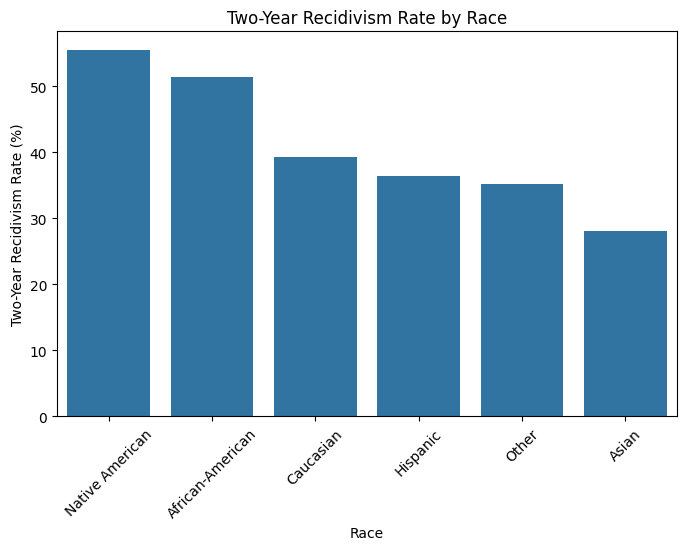

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=recid_by_race.sort_values(by="recidivism_percent", ascending=False),
    x="race",
    y="recidivism_percent"
)

plt.title("Two-Year Recidivism Rate by Race")
plt.xlabel("Race")
plt.ylabel("Two-Year Recidivism Rate (%)")
plt.xticks(rotation=45)
plt.show()

There are different rates across the race by two years of recidivism. The African American defendants have a higher observed recidivism rate than Caucasian defendants in this datset. This is important that different base rates across groups can create fairness trade-offs later. The minority of race for Asian and Native American defendants needs careful interpretation due to low race compare to African American and Caucasian.

Due to unbalance of the race, let's get into more analysis with other features. We will use COMPAS score category by race


In [ ]:
risk_by_race_percent = pd.crosstab(
    df_focus["race"],
    df_focus["score_text"],
    normalize="index"
) * 100

risk_by_race_percent

score_text,High,Low,Medium
race,,,
African-American,27.732684,41.179654,31.087662
Asian,9.375000,75.000000,15.625000
Caucasian,11.246944,65.199674,23.553382
Hispanic,10.518053,70.172684,19.309262
Native American,33.333333,33.333333,33.333333
Other,6.896552,79.045093,14.058355


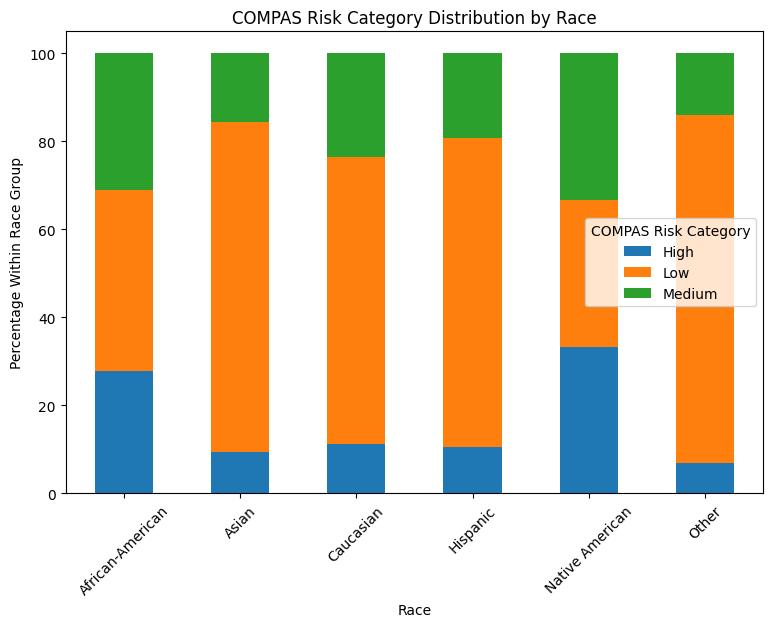

In [ ]:
risk_by_race_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

plt.title("COMPAS Risk Category Distribution by Race")
plt.xlabel("Race")
plt.ylabel("Percentage Within Race Group")
plt.xticks(rotation=45)
plt.legend(title="COMPAS Risk Category")
plt.show()

COMPAS risk categories are distributed differently across racial groups. African-American defendants have a larger percentage of High and Medium risk labels, while Caucasian defendants have a larger percentage of Low risk labels. This pattern is directly relevant to the fairness audit because risk categories may influence decisions about pretrial release, supervision, or sentencing.

Let's look at the prior offense count by race.

In [ ]:
priors_by_race = (
    df_focus
    .groupby("race")["priors_count"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

priors_by_race.sort_values(by="mean", ascending=False)

,race,count,mean,median,std
4,Native American,18,6.000000,2.5,7.661976
0,African-American,3696,4.438853,2.0,5.579835
2,Caucasian,2454,2.586797,1.0,3.798803
3,Hispanic,637,2.252747,1.0,3.647673
5,Other,377,1.875332,1.0,3.404917
1,Asian,32,1.437500,0.0,2.256710


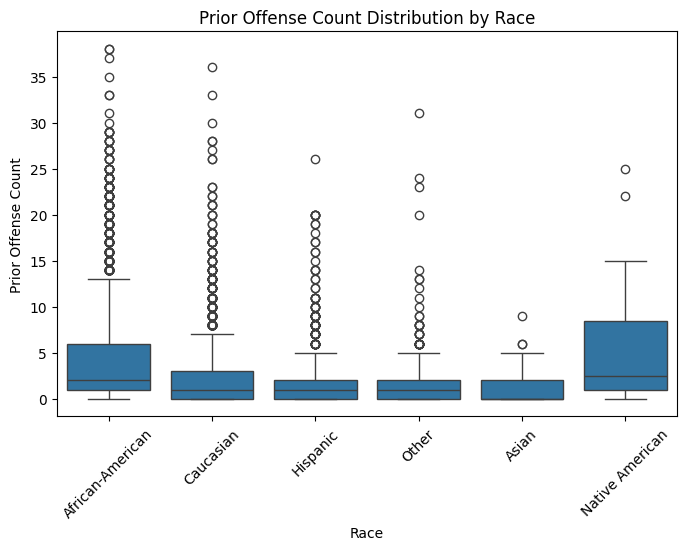

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_focus,
    x="race",
    y="priors_count",
    order=df_focus["race"].value_counts().index
)

plt.title("Prior Offense Count Distribution by Race")
plt.xlabel("Race")
plt.ylabel("Prior Offense Count")
plt.xticks(rotation=45)
plt.show()

Prior offense count is an import predictor for recidivism, but it may also operate as a proxy variable. African-American defendants have a higher average prior offense count than Caucasian defendants in this dataset. From a criminal justice perspective, this variable is domain-relevant because past offenses can be related to future recidivism risk. However, it may also reflect unequal policing, arrest patterns, and justice-system contact. Therefore, even if race is not directly used in the model, variables like priors_count may still contribute to racially different predictions.

## Model

To develop the model for residivism of two years records, we establish the pipelline using scikit-learn that it is tuning hyper parameters inside GridSearch with calibration measuring the proper probabilties instead of doing it all at once to reduce the cost of time.

- Numeric features were processed using imputer of median.

- Categorical fetures were processed using imputer of most frequent values and hot encoder.

- We will use GridSearchCV for cross-validation with scoring the brier score because we are doing calibrated model.

- The preprocessed data was then passed to XGBoost Classifier model with calibration.

We will not put the race feature considering bias of predicting residivism across race that has unbalanced in the data. We will use it later for comparing the fairness audit.

Let's prepare for the data of train test split.

In [ ]:
# Target variable
target = "two_year_recid"

# Protected attribute for later fairness audit
protected_attribute = "race"

# Model input features
model_features = [
    "sex",
    "age",
    "age_cat",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "priors_count",
    "c_charge_degree"
]

X = df_focus[model_features].copy()
y = df_focus[target].copy()

# Keep race separately for disaggregated evaluation
race_group = df_focus[protected_attribute].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Race group shape:", race_group.shape)

X shape: (7214, 8)
y shape: (7214,)
Race group shape: (7214,)


In [ ]:

X_train, X_test, y_train, y_test, race_train, race_test = train_test_split(
    X,
    y,
    race_group,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set shape: (5771, 8)
Testing set shape: (1443, 8)

Training target distribution:
two_year_recid
0    0.549298
1    0.450702
Name: proportion, dtype: float64

Testing target distribution:
two_year_recid
0    0.54955
1    0.45045
Name: proportion, dtype: float64


In [ ]:
categorical_features = [
    "sex",
    "age_cat",
    "c_charge_degree"
]

numeric_features = [
    "age",
    "juv_fel_count",
    "juv_misd_count",
    "juv_other_count",
    "priors_count"
]

# Categorical preprocessing:
# 1. Fill missing categorical values with the most frequent category
# 2. One-hot encode categorical variables
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Numeric preprocessing:
# 1. Fill missing numeric values with the median
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_transformer, categorical_features),
        ("num", numeric_transformer, numeric_features)
    ]
)

In [ ]:


xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_pipeline = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", xgb_model)
    ]
)

calibrated_xgb = CalibratedClassifierCV(
    estimator=xgb_pipeline,
    method="sigmoid",
    cv=3
)

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "estimator__model__n_estimators": [100, 200, 500],
    "estimator__model__max_depth": [2, 3, 4],

}

grid_search = GridSearchCV(
    estimator=calibrated_xgb,
    param_grid=param_grid,
    scoring="neg_brier_score",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 9 candidates, totalling 27 fits


GridSearchCV(cv=3,
             estimator=CalibratedClassifierCV(cv=3,
                                              estimator=Pipeline(steps=[('preprocess',
                                                                         ColumnTransformer(transformers=[('cat',
                                                                                                          Pipeline(steps=[('imputer',
                                                                                                                           SimpleImputer(strategy='most_frequent')),
                                                                                                                          ('onehot',
                                                                                                                           OneHotEncoder(handle_unknown='ignore'))]),
                                                                                                          ['sex',
                                                                                                           'age_cat',
                                                                                                           'c_charge_degree']),
                                                                                                         ('num',
                                                                                                          Pipeline(steps=[('imputer',
                                                                                                                           SimpleImputer(strategy='...
                                                                                       max_cat_to_onehot=None,
                                                                                       max_delta_step=None,
                                                                                       max_depth=None,
                                                                                       max_leaves=None,
                                                                                       min_child_weight=None,
                                                                                       missing=nan,
                                                                                       monotone_constraints=None,
                                                                                       multi_strategy=None,
                                                                                       n_estimators=None,
                                                                                       n_jobs=-1,
                                                                                       num_parallel_tree=None, ...))])),
             n_jobs=-1,
             param_grid={'estimator__model__max_depth': [2, 3, 4],
                         'estimator__model__n_estimators': [100, 200, 500]},
             scoring='neg_brier_score', verbose=1)

In [ ]:
grid_search.best_params_

{'estimator__model__max_depth': 2, 'estimator__model__n_estimators': 100}

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "estimator__model__n_estimators": [100],
    "estimator__model__max_depth": [2],
    "estimator__model__learning_rate": [0.03, 0.05, 0.10],
    "estimator__model__subsample": [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=calibrated_xgb,
    param_grid=param_grid,
    scoring="neg_brier_score",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 6 candidates, totalling 18 fits


GridSearchCV(cv=3,
             estimator=CalibratedClassifierCV(cv=3,
                                              estimator=Pipeline(steps=[('preprocess',
                                                                         ColumnTransformer(transformers=[('cat',
                                                                                                          Pipeline(steps=[('imputer',
                                                                                                                           SimpleImputer(strategy='most_frequent')),
                                                                                                                          ('onehot',
                                                                                                                           OneHotEncoder(handle_unknown='ignore'))]),
                                                                                                          ['sex',
                                                                                                           'age_cat',
                                                                                                           'c_charge_degree']),
                                                                                                         ('num',
                                                                                                          Pipeline(steps=[('imputer',
                                                                                                                           SimpleImputer(strategy='...
                                                                                       min_child_weight=None,
                                                                                       missing=nan,
                                                                                       monotone_constraints=None,
                                                                                       multi_strategy=None,
                                                                                       n_estimators=None,
                                                                                       n_jobs=-1,
                                                                                       num_parallel_tree=None, ...))])),
             n_jobs=-1,
             param_grid={'estimator__model__learning_rate': [0.03, 0.05, 0.1],
                         'estimator__model__max_depth': [2],
                         'estimator__model__n_estimators': [100],
                         'estimator__model__subsample': [0.8, 1.0]},
             scoring='neg_brier_score', verbose=1)

In [ ]:
grid_search.best_params_

{'estimator__model__learning_rate': 0.05,
 'estimator__model__max_depth': 2,
 'estimator__model__n_estimators': 100,
 'estimator__model__subsample': 0.8}

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "estimator__model__n_estimators": [100],
    "estimator__model__max_depth": [2],
    "estimator__model__learning_rate": [0.05],
    "estimator__model__subsample": [0.8],
    "estimator__model__colsample_bytree": [0.5,0.8, 1.0],
    "estimator__model__min_child_weight": [1, 5, 7]
}

grid_search = GridSearchCV(
    estimator=calibrated_xgb,
    param_grid=param_grid,
    scoring="neg_brier_score",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 9 candidates, totalling 27 fits


GridSearchCV(cv=3,
             estimator=CalibratedClassifierCV(cv=3,
                                              estimator=Pipeline(steps=[('preprocess',
                                                                         ColumnTransformer(transformers=[('cat',
                                                                                                          Pipeline(steps=[('imputer',
                                                                                                                           SimpleImputer(strategy='most_frequent')),
                                                                                                                          ('onehot',
                                                                                                                           OneHotEncoder(handle_unknown='ignore'))]),
                                                                                                          ['sex',
                                                                                                           'age_cat',
                                                                                                           'c_charge_degree']),
                                                                                                         ('num',
                                                                                                          Pipeline(steps=[('imputer',
                                                                                                                           SimpleImputer(strategy='...
                                                                                       n_estimators=None,
                                                                                       n_jobs=-1,
                                                                                       num_parallel_tree=None, ...))])),
             n_jobs=-1,
             param_grid={'estimator__model__colsample_bytree': [0.5, 0.8, 1.0],
                         'estimator__model__learning_rate': [0.05],
                         'estimator__model__max_depth': [2],
                         'estimator__model__min_child_weight': [1, 5, 7],
                         'estimator__model__n_estimators': [100],
                         'estimator__model__subsample': [0.8]},
             scoring='neg_brier_score', verbose=1)

In [ ]:
grid_search.best_params_

{'estimator__model__colsample_bytree': 0.8,
 'estimator__model__learning_rate': 0.05,
 'estimator__model__max_depth': 2,
 'estimator__model__min_child_weight': 7,
 'estimator__model__n_estimators': 100,
 'estimator__model__subsample': 0.8}

These are the best parameter while we tuned the model.

## Result

Let's see our model results measuring the accuracy, recall, precision, f1-score, roc_auc score.

In [ ]:
print("Best GridSearchCV score:", grid_search.best_score_)
print("Best parameters:")
print(grid_search.best_params_)

best_model = grid_search.best_estimator_

Best GridSearchCV score: -0.20712945139707614
Best parameters:
{'estimator__model__colsample_bytree': 0.8, 'estimator__model__learning_rate': 0.05, 'estimator__model__max_depth': 2, 'estimator__model__min_child_weight': 7, 'estimator__model__n_estimators': 100, 'estimator__model__subsample': 0.8}


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    classification_report,
    confusion_matrix
)

# Predicted probabilities
y_test_proba = best_model.predict_proba(X_test)[:, 1]

# Convert probabilities to binary predictions using 0.50 threshold
y_test_pred = (y_test_proba >= 0.50).astype(int)

# Overall metrics
overall_metrics = {
    "accuracy": accuracy_score(y_test, y_test_pred),
    "precision": precision_score(y_test, y_test_pred, zero_division=0),
    "recall": recall_score(y_test, y_test_pred, zero_division=0),
    "f1_score": f1_score(y_test, y_test_pred, zero_division=0),
    "auc_roc": roc_auc_score(y_test, y_test_proba),
    "brier_score": brier_score_loss(y_test, y_test_proba)
}

overall_metrics_df = pd.DataFrame([overall_metrics])
overall_metrics_df

,accuracy,precision,recall,f1_score,auc_roc,brier_score
0,0.693001,0.68,0.601538,0.638367,0.735665,0.205435


In [ ]:
print("Classification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.77      0.73       793
           1       0.68      0.60      0.64       650

    accuracy                           0.69      1443
   macro avg       0.69      0.68      0.69      1443
weighted avg       0.69      0.69      0.69      1443

Confusion Matrix:
[[609 184]
 [259 391]]


The model achieved an overall accuracy of 69% that it correctly classified about that percentage defndants in the test set. The model AUC-ROC socre was 0.736 that moderate ability to distinguish between defendants who recidivated and those who did not. The model performed better for the no recidivism class than for recidivism class. The recall for class 0 was 0.77, while recall for class 1 was 0.6. This means the model was better at identifying defendants who did not recidivate than defendants who did recidivate. The confusion matrix shows 609 true negatives, 391 true positives, 184 false positives, and 259 false negatives. In the criminal justice context, false positives are concerning because they may lead to people being treated as higher risk even when they do not reoffend, while false negatives are concerning because they represent people predicted as lower risk who later recidivate. Overall, the model provides moderate predictive performance, but its errors have serious fairness.

Let's see the baseline performance metrics disaggregated by at race.

In [ ]:
def performance_by_group(y_true, y_pred, y_proba, group):
    results = []

    y_true = pd.Series(y_true).reset_index(drop=True)
    y_pred = pd.Series(y_pred).reset_index(drop=True)
    y_proba = pd.Series(y_proba).reset_index(drop=True)
    group = pd.Series(group).reset_index(drop=True)

    for group_value in sorted(group.unique()):
        mask = group == group_value

        y_true_g = y_true[mask]
        y_pred_g = y_pred[mask]
        y_proba_g = y_proba[mask]

        if len(np.unique(y_true_g)) == 2:
            auc_g = roc_auc_score(y_true_g, y_proba_g)
        else:
            auc_g = np.nan

        results.append({
            "race": group_value,
            "n": mask.sum(),
            "accuracy": accuracy_score(y_true_g, y_pred_g),
            "precision": precision_score(y_true_g, y_pred_g, zero_division=0),
            "recall": recall_score(y_true_g, y_pred_g, zero_division=0),
            "f1_score": f1_score(y_true_g, y_pred_g, zero_division=0),
            "auc_roc": auc_g,
            "brier_score": brier_score_loss(y_true_g, y_proba_g)
        })

    return pd.DataFrame(results)


race_metrics = performance_by_group(
    y_true=y_test,
    y_pred=y_test_pred,
    y_proba=y_test_proba,
    group=race_test
)

race_metrics

,race,n,accuracy,precision,recall,f1_score,auc_roc,brier_score
0,African-American,736,0.701087,0.703704,0.711230,0.707447,0.750897,0.202672
1,Asian,4,0.750000,1.000000,0.500000,0.666667,1.000000,0.163570
2,Caucasian,486,0.683128,0.595420,0.435754,0.503226,0.670282,0.212884
3,Hispanic,126,0.650794,0.625000,0.462963,0.531915,0.729810,0.208530
4,Native American,5,0.800000,1.000000,0.500000,0.666667,1.000000,0.134591
5,Other,86,0.732558,0.833333,0.512821,0.634921,0.798963,0.188519


The disaggregated performance table shows that model performance differs across racial groups. The most reliable comparison is between African-American and Caucasian defendants because they have the largest test-set sample sizes. The model achieved an accuracy of 70.1% for African-American defendants and 68.3% for Caucasian defendants. However, the larger difference appears in recall: the model correctly identified 71.1% of African-American defendants who recidivated, compared with only 43.6% of Caucasian defendants who recidivated. This suggests that the model is more likely to miss Caucasian defendants who later recidivate. Precision and AUC-ROC are also higher for African-American defendants, indicating stronger predictive performance for that group. Metrics for Asian and Native American defendants should not be overinterpreted because their test-set sample sizes are very small. Overall, the disaggregated results show that the model does not perform equally across racial groups, which motivates the fairness audit in Phase 2.

## Fairness Audit

Let's calculate the fairness metrics by race between African-American and Caucasian. They have enough people to compare in terms of race.

In [ ]:
fairness_df = pd.DataFrame({
    "y_true": y_test.reset_index(drop=True),
    "y_pred": pd.Series(y_test_pred).reset_index(drop=True),
    "y_proba": pd.Series(y_test_proba).reset_index(drop=True),
    "race": race_test.reset_index(drop=True)
})

# Focus on the two largest racial groups
fairness_focus = fairness_df[
    fairness_df["race"].isin(["African-American", "Caucasian"])
].copy()

fairness_focus.head()

,y_true,y_pred,y_proba,race
0,1,0,0.365954,African-American
1,0,0,0.274951,African-American
2,1,0,0.495610,Caucasian
4,1,1,0.792962,African-American
5,0,0,0.415109,Caucasian


In [ ]:
from sklearn.metrics import confusion_matrix

def group_fairness_metrics(data, group_col="race", y_true_col="y_true", y_pred_col="y_pred"):
    results = []

    for group in sorted(data[group_col].unique()):
        group_data = data[data[group_col] == group]

        y_true_g = group_data[y_true_col]
        y_pred_g = group_data[y_pred_col]

        tn, fp, fn, tp = confusion_matrix(y_true_g, y_pred_g, labels=[0, 1]).ravel()

        # Core rates
        predicted_positive_rate = (tp + fp) / (tp + fp + tn + fn)
        true_positive_rate = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        false_positive_rate = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        positive_predictive_value = tp / (tp + fp) if (tp + fp) > 0 else np.nan
        false_negative_rate = fn / (fn + tp) if (fn + tp) > 0 else np.nan
        negative_predictive_value = tn / (tn + fn) if (tn + fn) > 0 else np.nan

        results.append({
            "race": group,
            "n": len(group_data),
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "demographic_parity_rate": predicted_positive_rate,
            "equality_of_opportunity_TPR": true_positive_rate,
            "false_positive_rate": false_positive_rate,
            "false_negative_rate": false_negative_rate,
            "predictive_parity_PPV": positive_predictive_value,
            "negative_predictive_value": negative_predictive_value
        })

    return pd.DataFrame(results)

fairness_metrics = group_fairness_metrics(fairness_focus)

fairness_metrics

,race,n,TN,FP,FN,TP,demographic_parity_rate,equality_of_opportunity_TPR,false_positive_rate,false_negative_rate,predictive_parity_PPV,negative_predictive_value
0,African-American,736,250,112,108,266,0.513587,0.711230,0.309392,0.288770,0.703704,0.698324
1,Caucasian,486,254,53,101,78,0.269547,0.435754,0.172638,0.564246,0.595420,0.715493


Demographic parity was not satisfied. The model predicted 51.4% of African-American defendants as high risk, compared with 27.0% of Caucasian defendants. This means African-American defendants were much more likely to receive an unfavorable high-risk prediction.

Equality of opportunity was not satisfied. The true positive rate was 71.1% for African-American defendants and 43.6% for Caucasian defendants. This means the model was much more likely to correctly identify actual recidivism among African-American defendants, while it missed more Caucasian defendants who later recidivated.

Equalized odds was not satisfied. The model had both a higher true positive rate and a higher false positive rate for African-American defendants than for Caucasian defendants. The false positive rate was 30.9% for African-American defendants compared with 17.3% for Caucasian defendants. This means African-American defendants who did not recidivate were more likely to be incorrectly labeled as high risk.

Predictive parity was not satisfied. The positive predictive value was 70.4% for African-American defendants and 59.5% for Caucasian defendants. This means that when the model predicted recidivism, the prediction was more often correct for African-American defendants than for Caucasian defendants.

Let's check the metric conflict and ethical priority.

In [ ]:
aa = fairness_metrics[fairness_metrics["race"] == "African-American"].iloc[0]
ca = fairness_metrics[fairness_metrics["race"] == "Caucasian"].iloc[0]

metric_comparison = pd.DataFrame({
    "metric": [
        "Demographic parity rate",
        "Equality of opportunity / TPR",
        "False positive rate",
        "False negative rate",
        "Predictive parity / PPV",
        "Negative predictive value"
    ],
    "African-American": [
        aa["demographic_parity_rate"],
        aa["equality_of_opportunity_TPR"],
        aa["false_positive_rate"],
        aa["false_negative_rate"],
        aa["predictive_parity_PPV"],
        aa["negative_predictive_value"]
    ],
    "Caucasian": [
        ca["demographic_parity_rate"],
        ca["equality_of_opportunity_TPR"],
        ca["false_positive_rate"],
        ca["false_negative_rate"],
        ca["predictive_parity_PPV"],
        ca["negative_predictive_value"]
    ]
})

metric_comparison["absolute_difference"] = (
    metric_comparison["African-American"] - metric_comparison["Caucasian"]
).abs()

metric_comparison

,metric,African-American,Caucasian,absolute_difference
0,Demographic parity rate,0.513587,0.269547,0.244040
1,Equality of opportunity / TPR,0.711230,0.435754,0.275476
2,False positive rate,0.309392,0.172638,0.136754
3,False negative rate,0.288770,0.564246,0.275476
4,Predictive parity / PPV,0.703704,0.595420,0.108284
5,Negative predictive value,0.698324,0.715493,0.017169


The first conflict is between demographic parity and equality of opportunity. The model predicts African-American defendants as high risk at a rate of 51.4%, while it predicts Caucasian defendants as high risk at only 27.0%. This creates a demographic parity gap of 24.4 percentage points. At the same time, the model has a much higher true positive rate for African-American defendants: 71.1% compared with 43.6% for Caucasian defendants. This means the model catches more actual recidivism among African-American defendants, but it also predicts African-American defendants as high risk much more often.

The second conflict is between false positives and false negatives. African-American defendants have a higher false positive rate: 30.9% compared with 17.3% for Caucasian defendants. This means African-American defendants who did not recidivate were more likely to be incorrectly labeled high risk. However, Caucasian defendants have a much higher false negative rate: 56.4% compared with 28.9% for African-American defendants. This means the model misses more Caucasian defendants who actually recidivate. These two errors create different harms. False positives can unfairly burden defendants who would not reoffend, while false negatives can create public safety concerns by missing people who later recidivate.

The third conflict is between predictive parity and equalized odds. Predictive parity is measured by positive predictive value. In my model, positive predictions are more reliable for African-American defendants: 70.4% compared with 59.5% for Caucasian defendants. However, even though the model’s high-risk predictions are more accurate for African-American defendants, the model still fails equalized odds because the true positive rate and false positive rate are not equal across groups. The true positive rate gap is 27.5 percentage points, and the false positive rate gap is 13.7 percentage points. This shows that a model can have stronger precision for one group while still creating unequal error rates across groups.

I would prioritize equalized odds, especially the false positive rate, using a fair ethics framework. Fair ethics focuses on whether benefits and harms are distributed fairly across groups. In this model, African-American defendants had a false positive rate of 30.9%, compared with 17.3% for Caucasian defendants. This means African-American defendants who did not recidivate were more often wrongly labeled high risk. In a criminal justice setting, that error can lead to stricter supervision, detention, stigma, or harsher treatment. Even though Caucasian defendants had a higher false negative rate, fair ethics requires attention to whether one protected group is carrying a larger burden of harmful mistakes. For that reason, I would prioritize reducing unequal false positive rates and moving the model closer to equalized odds.

## Explainability Analysis
### SHAPE Global Feature Importance

Let's refit our best model for SHAPE.

In [ ]:
# Get best parameters from GridSearchCV
best_params = grid_search.best_params_

# Convert GridSearch parameter names into XGBoost parameter names
xgb_best_params = {
    key.replace("estimator__model__", ""): value
    for key, value in best_params.items()
}

xgb_explain_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    **xgb_best_params
)

xgb_explain_pipeline = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", xgb_explain_model)
    ]
)

# Fit on training data
xgb_explain_pipeline.fit(X_train, y_train)

# Get feature names after preprocessing
feature_names = xgb_explain_pipeline.named_steps["preprocess"].get_feature_names_out()

feature_names


array(['cat__sex_Female', 'cat__sex_Male', 'cat__age_cat_25 - 45',
       'cat__age_cat_Greater than 45', 'cat__age_cat_Less than 25',
       'cat__c_charge_degree_F', 'cat__c_charge_degree_M', 'num__age',
       'num__juv_fel_count', 'num__juv_misd_count',
       'num__juv_other_count', 'num__priors_count'], dtype=object)

In [ ]:
# Transform test data using the fitted preprocessor
X_test_transformed = xgb_explain_pipeline.named_steps["preprocess"].transform(X_test)

# Convert to dense if needed
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Convert to dataframe for readability
X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names
)

X_test_transformed_df.head()

,cat__sex_Female,cat__sex_Male,cat__age_cat_25 - 45,cat__age_cat_Greater than 45,cat__age_cat_Less than 25,cat__c_charge_degree_F,cat__c_charge_degree_M,num__age,num__juv_fel_count,num__juv_misd_count,num__juv_other_count,num__priors_count
0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,47.0,0.0,0.0,0.0,3.0
1,0.0,1.0,1.0,0.0,0.0,1.0,0.0,35.0,0.0,0.0,0.0,1.0
2,0.0,1.0,1.0,0.0,0.0,1.0,0.0,27.0,0.0,0.0,0.0,2.0
3,0.0,1.0,0.0,0.0,1.0,1.0,0.0,23.0,0.0,0.0,0.0,6.0
4,0.0,1.0,1.0,0.0,0.0,1.0,0.0,27.0,0.0,0.0,0.0,11.0


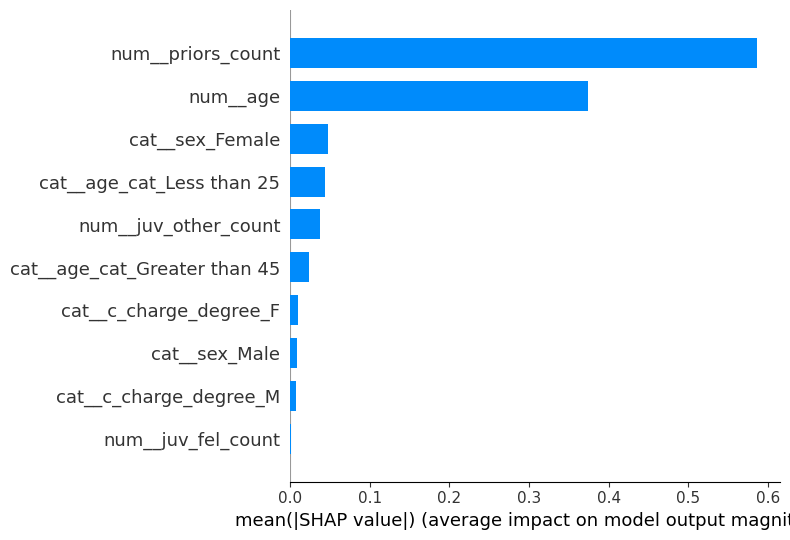

In [ ]:
# Extract trained XGBoost model
trained_xgb = xgb_explain_pipeline.named_steps["model"]

# Create SHAP explainer
explainer = shap.TreeExplainer(trained_xgb)

# Compute SHAP values
shap_values = explainer.shap_values(X_test_transformed_df)

shap.summary_plot(
    shap_values,
    X_test_transformed_df,
    plot_type="bar",
    max_display=10
)

In [ ]:
# Calculate mean absolute SHAP value for each feature
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
})

# Sort by importance
shap_importance = shap_importance.sort_values(
    by="mean_abs_shap",
    ascending=False
)

top_5_shap = shap_importance.head(5)

top_5_shap

,feature,mean_abs_shap
11,num__priors_count,0.585733
7,num__age,0.374578
0,cat__sex_Female,0.047018
4,cat__age_cat_Less than 25,0.044187
10,num__juv_other_count,0.037943


I applied SHAP to the XGBoost model to identify the global features most strongly driving predictions of two-year recidivism. The top five features were priors_count, age, sex_Female, age_cat_Less than 25, and juv_other_count. The most influential feature was priors_count, with a mean absolute SHAP value of 0.586, followed by age with a value of 0.375. These two features were much more influential than the remaining features, suggesting that the model relies heavily on prior criminal history and age when predicting recidivism. From a domain perspective, this makes sense because prior offenses and age are commonly associated with recidivism risk. However, these variables also raise fairness concerns. Prior offense count may reflect unequal policing, arrest patterns, and justice-system contact, meaning it can function as a proxy for race even when race is excluded from the model. Juvenile offense history, represented by juv_other_count, may similarly reflect early justice-system exposure shaped by school discipline, neighborhood policing, and socioeconomic factors. Therefore, the SHAP results show that removing race from the model does not fully remove the possibility of racial bias, because the model may still rely on variables that carry historical and institutional inequality.

### Recourse Test

For the criminal justice, the false positive rate is crucial that model predicting high risk, but the person did not actually recidivate.

In [ ]:
# Create recourse dataframe
recourse_df = X_test.copy()
recourse_df["y_true"] = y_test.values
recourse_df["y_pred"] = y_test_pred
recourse_df["y_proba"] = y_test_proba
recourse_df["race"] = race_test.values

# Select one unfavorable prediction:
# predicted high risk, but actually did not recidivate
false_positive_cases = recourse_df[
    (recourse_df["y_pred"] == 1) &
    (recourse_df["y_true"] == 0)
].copy()

false_positive_cases.head()

,sex,age,age_cat,juv_fel_count,juv_misd_count,juv_other_count,priors_count,c_charge_degree,y_true,y_pred,y_proba,race
3670,Male,33,25 - 45,0,0,0,8,F,0,1,0.698048,African-American
6234,Male,32,25 - 45,0,3,0,7,F,0,1,0.712478,African-American
5595,Male,29,25 - 45,0,0,0,4,M,0,1,0.641146,African-American
1088,Male,37,25 - 45,2,0,0,18,M,0,1,0.752561,African-American
5452,Female,27,25 - 45,0,0,0,6,F,0,1,0.662924,Caucasian


Let's choose one case of person.

In [ ]:
# Pick the first false positive case
person_index = false_positive_cases.index[0]

person = X_test.loc[[person_index]].copy()

person

,sex,age,age_cat,juv_fel_count,juv_misd_count,juv_other_count,priors_count,c_charge_degree
3670,Male,33,25 - 45,0,0,0,8,F


Let's predict that person in the model.

In [ ]:
original_probability = best_model.predict_proba(person)[:, 1][0]
original_prediction = int(original_probability >= 0.50)

print("Original predicted probability:", original_probability)
print("Original predicted class:", original_prediction)

Original predicted probability: 0.6980478919435856
Original predicted class: 1


It shows that person was recidivated in probability of 0.69. Let's adjust the features like lower the priors count, older age, different age cate, lower juvenile offense count, misdemeanor instead of felony.

In [ ]:
counterfactuals = []

def test_counterfactual(description, modified_person):
    proba = best_model.predict_proba(modified_person)[:, 1][0]
    pred = int(proba >= 0.50)

    counterfactuals.append({
        "change": description,
        "predicted_probability": proba,
        "predicted_class": pred
    })


# Original
test_counterfactual("Original case", person.copy())

# Change 1: reduce priors_count to 0
p1 = person.copy()
p1["priors_count"] = 0
test_counterfactual("Set priors_count to 0", p1)

# Change 2: reduce juvenile other count to 0
p2 = person.copy()
p2["juv_other_count"] = 0
test_counterfactual("Set juv_other_count to 0", p2)

# Change 3: reduce all juvenile counts to 0
p3 = person.copy()
p3["juv_fel_count"] = 0
p3["juv_misd_count"] = 0
p3["juv_other_count"] = 0
test_counterfactual("Set all juvenile counts to 0", p3)

# Change 4: make current charge a misdemeanor
p4 = person.copy()
p4["c_charge_degree"] = "M"
test_counterfactual("Change current charge degree to M", p4)

# Change 5: increase age to 46 and age category to Greater than 45
p5 = person.copy()
p5["age"] = 46
p5["age_cat"] = "Greater than 45"
test_counterfactual("Set age to 46 and age_cat to Greater than 45", p5)

# Change 6: combined more favorable profile
p6 = person.copy()
p6["priors_count"] = 0
p6["juv_fel_count"] = 0
p6["juv_misd_count"] = 0
p6["juv_other_count"] = 0
p6["c_charge_degree"] = "M"
p6["age"] = 46
p6["age_cat"] = "Greater than 45"
test_counterfactual("Combined: priors=0, juvenile counts=0, misdemeanor, age=46", p6)

counterfactual_results = pd.DataFrame(counterfactuals)
counterfactual_results

,change,predicted_probability,predicted_class
0,Original case,0.698048,1
1,Set priors_count to 0,0.259494,0
2,Set juv_other_count to 0,0.698048,1
3,Set all juvenile counts to 0,0.698048,1
4,Change current charge degree to M,0.688203,1
5,Set age to 46 and age_cat to Greater than 45,0.554056,1
6,"Combined: priors=0, juvenile counts=0, misdeme...",0.197499,0


The most important individual change was reducing priors_count to 0. This lowered the predicted probability from 0.698 to 0.259 and changed the prediction from high risk to low risk. This matches the SHAP analysis, where priors_count was the most important feature in the model. Changing juvenile offense counts did not affect this individual prediction, and changing the current charge degree to misdemeanor only slightly reduced the predicted probability from 0.698 to 0.688. Changing the person’s age to 46 reduced the probability to 0.554, but the model still predicted high risk. Only the prior-count change by itself, or the combined favorable scenario, changed the prediction to favorable.

However, most of these changes are not realistically actionable for the affected person. A defendant cannot erase their prior criminal record at the time of assessment. Juvenile history is also historical and cannot be changed. Age is not immediately actionable because a person cannot simply become older to receive a better prediction. Current charge degree may be partly contestable through a legal process, but it is not directly controlled by the defendant. Therefore, the model gives an explanation that is understandable but not very useful as practical recourse.

A non-technical person could understand the explanation if it were stated plainly: “The model classified you as high risk mainly because of your prior offense count. If your prior offense count were zero, the model would classify you as lower risk.” However, this explanation does not give the person a realistic action they can take, unless the prior-record information is incorrect and can be challenged.

Under GDPR Article 22, a person has the right not to be subject to a decision based solely on automated processing, including profiling, when that decision creates legal effects or similarly significant effects. A recidivism prediction used in bail, detention, supervision, or sentencing could have this kind of serious effect because it may influence a person’s liberty. Article 22 also states that exceptions may apply, such as when the decision is authorized by law or based on explicit consent, but safeguards must protect the person’s rights, freedoms, and legitimate interests. One important safeguard is the right to obtain human intervention.

Based on my recourse test, the model only partially satisfies the idea behind Article 22. The explanation is understandable because it identifies that prior offense count was the main reason for the unfavorable prediction. However, it is weak as a right-to-explanation tool because the main change needed for a favorable outcome is not actionable. To better align with GDPR Article 22, the system should not use the model as the sole basis for a legally significant decision. It should provide human review, allow the defendant to contest incorrect prior-record information, allow the person to explain their circumstances, and clearly communicate that the risk score is only one piece of evidence rather than a final decision.